# 04 — Complaint Analysis

This notebook will analyze project-portal complaints after residents begin submitting them. It is separate from the survey responses.

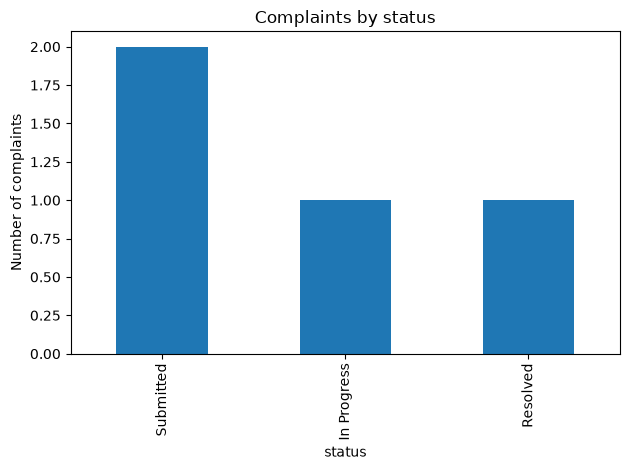

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Find the local complaint database.
project_folder = Path.cwd().parent
complaint_database = project_folder / 'complaints.db'

# Show a helpful message if no complaints have been saved yet.
if not complaint_database.exists():
    print('No complaint database yet. Run app.py and register a test complaint first.')
else:
    # Read complaint records from the database.
    with sqlite3.connect(complaint_database) as connection:
        complaints = pd.read_sql_query('SELECT * FROM complaints', connection)

    if complaints.empty:
        print('No complaints have been registered yet.')
    else:
        # Count complaints by their current status.
        status_counts = complaints['status'].value_counts()
        status_counts.plot(kind='bar', title='Complaints by status')
        plt.ylabel('Number of complaints')
        plt.tight_layout()
        plt.show()